In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

project_root = Path.cwd().parent
csv_path = project_root / "data" / "shopping_trends.csv"

df = pd.read_csv(csv_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (3900, 19)


,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Credit Card,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Bank Transfer,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Cash,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,PayPal,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Cash,Free Shipping,Yes,Yes,31,PayPal,Annually


In [2]:

# ==========================================
# CUSTOMER SHOPPING BEHAVIOR ANALYSIS
# ANALYSIS CELL
# ==========================================

# 1. Dataset overview
print("=" * 50)
print("1. DATASET OVERVIEW")
print("=" * 50)

print("Rows and columns:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\nColumn data types:")
display(df.dtypes)

print("\nMissing values by column:")
display(df.isnull().sum())

# 2. Numerical summary
print("\n" + "=" * 50)
print("2. NUMERICAL SUMMARY")
print("=" * 50)

display(df.describe(include="number").round(2))

# 3. Product category analysis
print("\n" + "=" * 50)
print("3. PRODUCT CATEGORY ANALYSIS")
print("=" * 50)

category_analysis = (
    df.groupby("Category")
      .agg(
          Purchase_Count=("Customer ID", "count"),
          Total_Purchase_Amount=("Purchase Amount (USD)", "sum"),
          Average_Purchase_Amount=("Purchase Amount (USD)", "mean")
      )
      .sort_values("Purchase_Count", ascending=False)
)

display(category_analysis.round(2))

# 4. Gender-based spending
print("\n" + "=" * 50)
print("4. GENDER-BASED SPENDING")
print("=" * 50)

gender_analysis = (
    df.groupby("Gender")
      .agg(
          Customer_Count=("Customer ID", "nunique"),
          Average_Purchase=("Purchase Amount (USD)", "mean"),
          Total_Purchase_Amount=("Purchase Amount (USD)", "sum")
      )
      .sort_values("Average_Purchase", ascending=False)
)

display(gender_analysis.round(2))

# 5. Age group analysis
print("\n" + "=" * 50)
print("5. AGE GROUP ANALYSIS")
print("=" * 50)

df["Age Group"] = pd.cut(
    df["Age"],
    bins=[0, 20, 30, 40, 50, 60, float("inf")],
    labels=["20 or younger", "21-30", "31-40",
            "41-50", "51-60", "Over 60"],
    include_lowest=True
)

age_analysis = (
    df.groupby("Age Group", observed=False)
      .agg(
          Customer_Count=("Customer ID", "nunique"),
          Average_Purchase=("Purchase Amount (USD)", "mean")
      )
)

display(age_analysis.round(2))

# 6. Payment method analysis
print("\n" + "=" * 50)
print("6. PAYMENT METHOD ANALYSIS")
print("=" * 50)

payment_analysis = df["Payment Method"].value_counts().to_frame(
    name="Purchase_Count"
)

display(payment_analysis)

# 7. Purchase frequency analysis
print("\n" + "=" * 50)
print("7. PURCHASE FREQUENCY ANALYSIS")
print("=" * 50)

frequency_analysis = (
    df.groupby("Frequency of Purchases")
      .agg(
          Customer_Count=("Customer ID", "nunique"),
          Average_Purchase=("Purchase Amount (USD)", "mean"),
          Total_Purchase_Amount=("Purchase Amount (USD)", "sum")
      )
      .sort_values("Customer_Count", ascending=False)
)

display(frequency_analysis.round(2))

# 8. Purchase history analysis
print("\n" + "=" * 50)
print("8. CUSTOMER PURCHASE HISTORY")
print("=" * 50)

print("Unique customer IDs:", df["Customer ID"].nunique())
print(
    "Customers appearing in multiple rows:",
    (df["Customer ID"].value_counts() > 1).sum()
)

if "Previous Purchases" in df.columns:
    print("\nPrevious purchases summary:")
    display(df["Previous Purchases"].describe().round(2))

# 9. Overall purchase statistics
print("\n" + "=" * 50)
print("9. OVERALL PURCHASE STATISTICS")
print("=" * 50)

print(
    "Average purchase amount: $",
    round(df["Purchase Amount (USD)"].mean(), 2)
)
print(
    "Median purchase amount: $",
    round(df["Purchase Amount (USD)"].median(), 2)
)
print(
    "Highest recorded purchase amount: $",
    df["Purchase Amount (USD)"].max()
)
print(
    "Lowest recorded purchase amount: $",
    df["Purchase Amount (USD)"].min()
)

print(
    "\nMost popular category:",
    df["Category"].value_counts().idxmax()
)
print(
    "Highest average-spending category:",
    df.groupby("Category")["Purchase Amount (USD)"].mean().idxmax()
)
print(
    "Most common payment method:",
    df["Payment Method"].value_counts().idxmax()
)
print(
    "Most common purchase frequency:",
    df["Frequency of Purchases"].value_counts().idxmax()
)

# 10. Correlation analysis
print("\n" + "=" * 50)
print("10. NUMERICAL CORRELATION")
print("=" * 50)

numeric_df = df.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()

display(correlation_matrix.round(2))

print("\nAnalysis completed successfully.")


1. DATASET OVERVIEW
Rows and columns: (3900, 19)
Duplicate rows: 0
Total missing values: 0

Column data types:


Customer ID                   int64
Age                           int64
Gender                          str
Item Purchased                  str
Category                        str
Purchase Amount (USD)         int64
Location                        str
Size                            str
Color                           str
Season                          str
Review Rating               float64
Subscription Status             str
Payment Method                  str
Shipping Type                   str
Discount Applied                str
Promo Code Used                 str
Previous Purchases            int64
Preferred Payment Method        str
Frequency of Purchases          str
dtype: object


Missing values by column:


Customer ID                 0
Age                         0
Gender                      0
Item Purchased              0
Category                    0
Purchase Amount (USD)       0
Location                    0
Size                        0
Color                       0
Season                      0
Review Rating               0
Subscription Status         0
Payment Method              0
Shipping Type               0
Discount Applied            0
Promo Code Used             0
Previous Purchases          0
Preferred Payment Method    0
Frequency of Purchases      0
dtype: int64


2. NUMERICAL SUMMARY


...


8. CUSTOMER PURCHASE HISTORY
Unique customer IDs: 3900
Customers appearing in multiple rows: 0

Previous purchases summary:


count    3900.00
mean       25.35
std        14.45
min         1.00
25%        13.00
50%        25.00
75%        38.00
max        50.00
Name: Previous Purchases, dtype: float64


9. OVERALL PURCHASE STATISTICS
Average purchase amount: $ 59.76
Median purchase amount: $ 60.0
Highest recorded purchase amount: $ 100
Lowest recorded purchase amount: $ 20

Most popular category: Clothing
Highest average-spending category: Footwear
Most common payment method: Credit Card
Most common purchase frequency: Every 3 Months

10. NUMERICAL CORRELATION


,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
Customer ID,1.00,-0.00,0.01,0.00,-0.04
Age,-0.00,1.00,-0.01,-0.02,0.04
Purchase Amount (USD),0.01,-0.01,1.00,0.03,0.01
Review Rating,0.00,-0.02,0.03,1.00,0.00
Previous Purchases,-0.04,0.04,0.01,0.00,1.00



Analysis completed successfully.


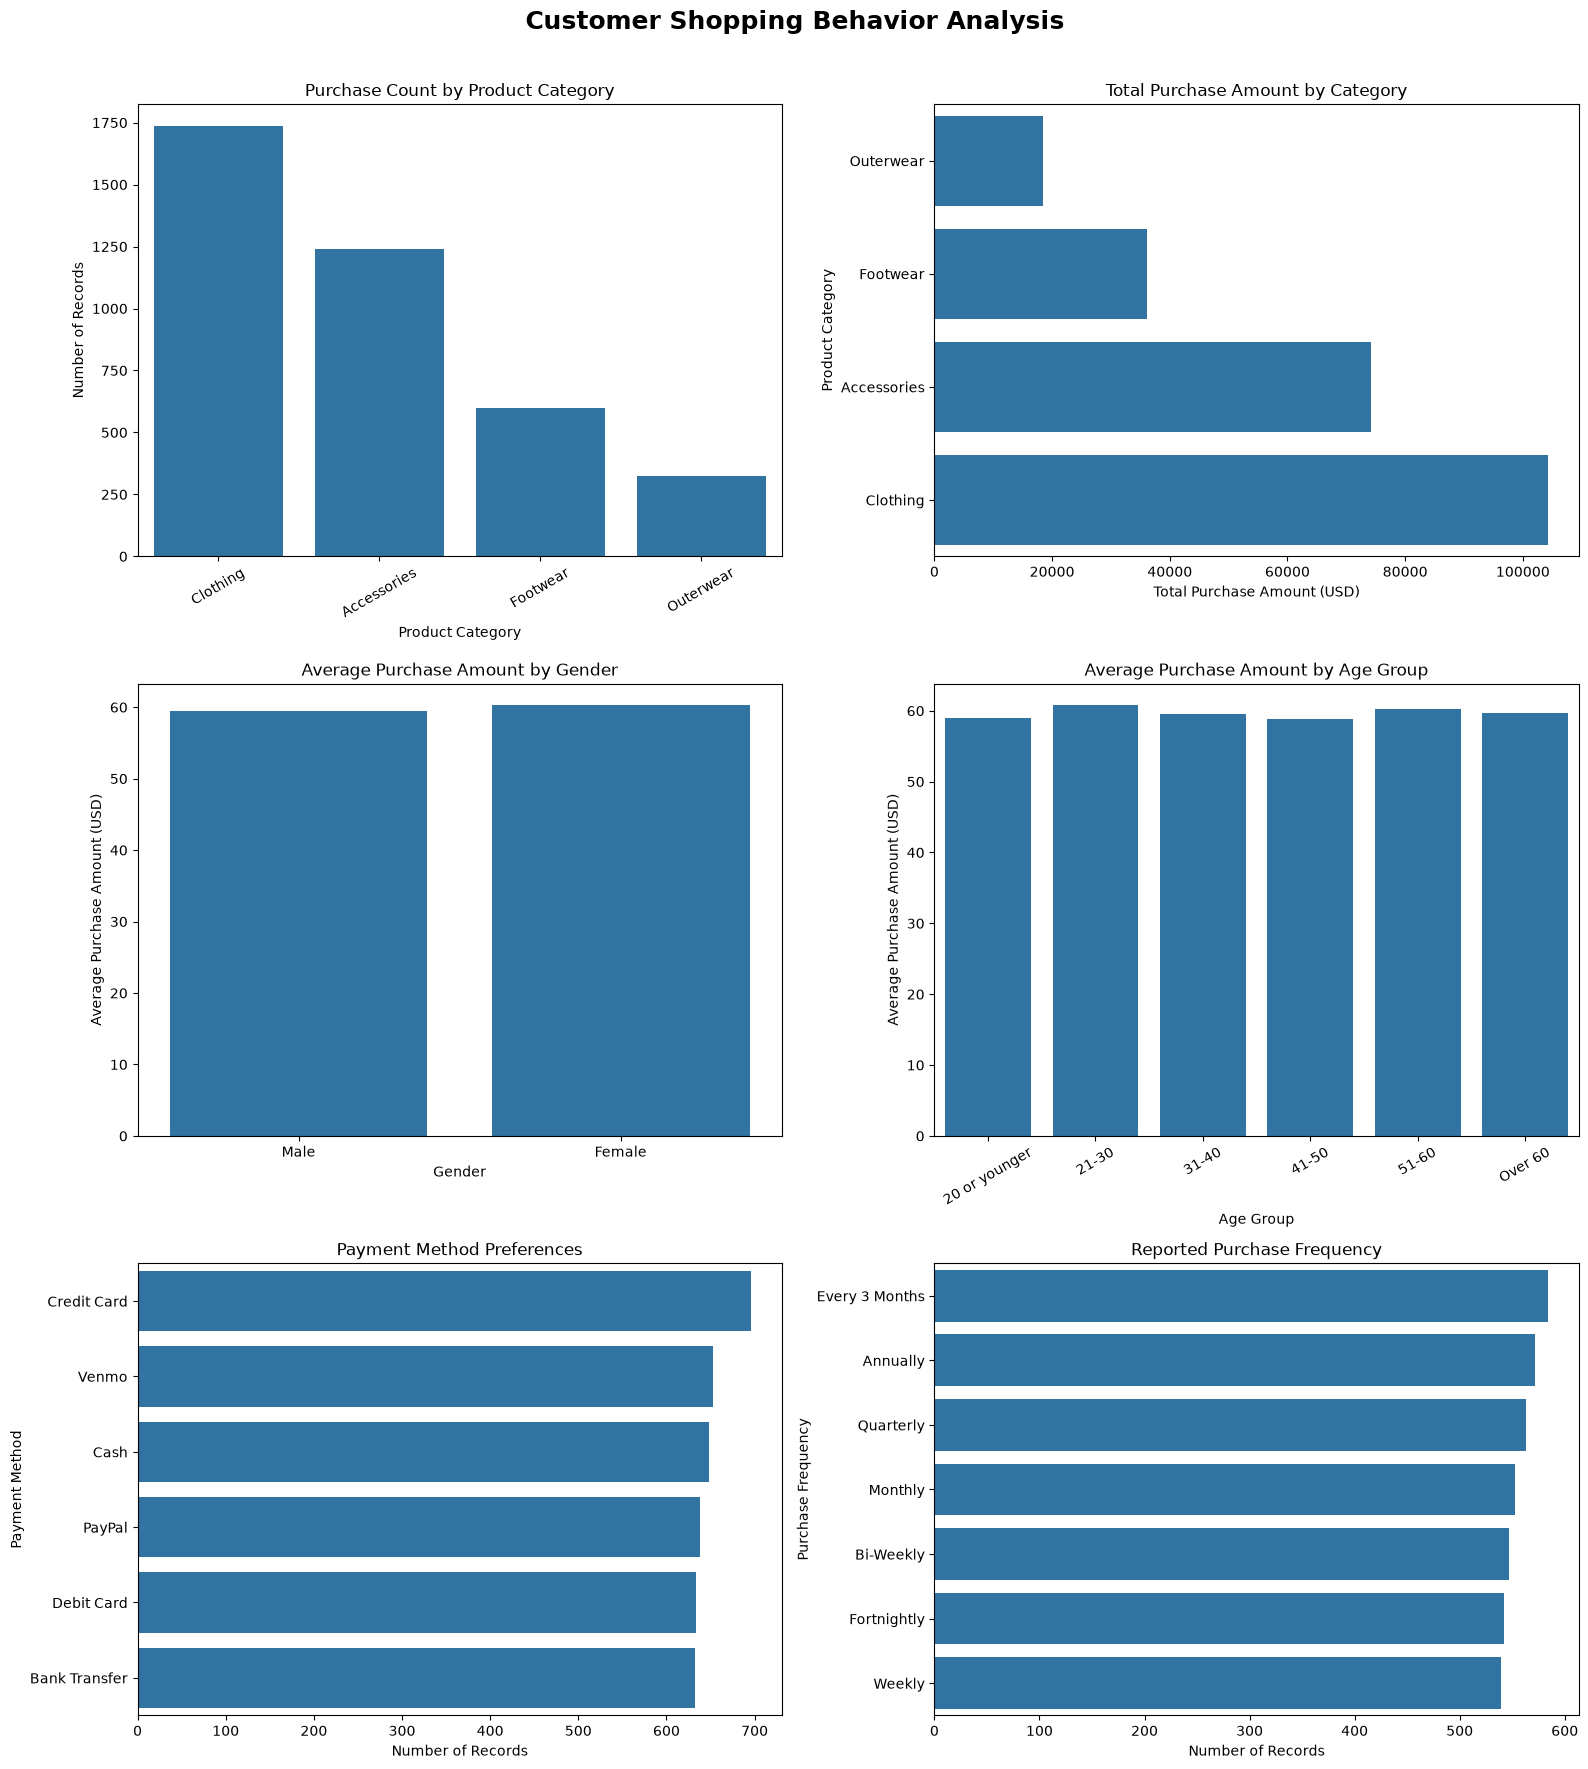

In [3]:

# ==========================================
# CUSTOMER SHOPPING BEHAVIOR ANALYSIS
# VISUALIZATION CELL
# ==========================================

fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# Chart 1: Most popular product categories
category_order = df["Category"].value_counts().index

sns.countplot(
    data=df,
    x="Category",
    order=category_order,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Purchase Count by Product Category")
axes[0, 0].set_xlabel("Product Category")
axes[0, 0].set_ylabel("Number of Records")
axes[0, 0].tick_params(axis="x", rotation=30)

# Chart 2: Total recorded purchase amount by category
category_totals = (
    df.groupby("Category")["Purchase Amount (USD)"]
      .sum()
      .sort_values()
)

sns.barplot(
    x=category_totals.values,
    y=category_totals.index,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Total Purchase Amount by Category")
axes[0, 1].set_xlabel("Total Purchase Amount (USD)")
axes[0, 1].set_ylabel("Product Category")

# Chart 3: Average spending by gender
sns.barplot(
    data=df,
    x="Gender",
    y="Purchase Amount (USD)",
    errorbar=None,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Average Purchase Amount by Gender")
axes[1, 0].set_xlabel("Gender")
axes[1, 0].set_ylabel("Average Purchase Amount (USD)")

# Chart 4: Average spending by age group
sns.barplot(
    data=df,
    x="Age Group",
    y="Purchase Amount (USD)",
    errorbar=None,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Average Purchase Amount by Age Group")
axes[1, 1].set_xlabel("Age Group")
axes[1, 1].set_ylabel("Average Purchase Amount (USD)")
axes[1, 1].tick_params(axis="x", rotation=30)

# Chart 5: Most common payment methods
payment_order = df["Payment Method"].value_counts().index

sns.countplot(
    data=df,
    y="Payment Method",
    order=payment_order,
    ax=axes[2, 0]
)

axes[2, 0].set_title("Payment Method Preferences")
axes[2, 0].set_xlabel("Number of Records")
axes[2, 0].set_ylabel("Payment Method")

# Chart 6: Reported purchase frequency
frequency_order = df["Frequency of Purchases"].value_counts().index

sns.countplot(
    data=df,
    y="Frequency of Purchases",
    order=frequency_order,
    ax=axes[2, 1]
)

axes[2, 1].set_title("Reported Purchase Frequency")
axes[2, 1].set_xlabel("Number of Records")
axes[2, 1].set_ylabel("Purchase Frequency")

fig.suptitle(
    "Customer Shopping Behavior Analysis",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [4]:

# ==========================================
# KEY BUSINESS INSIGHTS
# ==========================================

print("=" * 55)
print("       CUSTOMER SHOPPING BEHAVIOR: KEY INSIGHTS")
print("=" * 55)

# 1. Most popular product category
category_counts = df["Category"].value_counts()
top_category = category_counts.idxmax()

print(f"\n1. Most popular category: {top_category}")
print(f"   Purchase records: {category_counts.max():,}")

# 2. Category with highest average purchase amount
avg_by_category = (
    df.groupby("Category")["Purchase Amount (USD)"].mean()
)
top_avg_category = avg_by_category.idxmax()

print(f"\n2. Highest average-spending category: {top_avg_category}")
print(f"   Average purchase: ${avg_by_category.max():.2f}")

# 3. Category with highest total purchase amount
total_by_category = (
    df.groupby("Category")["Purchase Amount (USD)"].sum()
)
top_total_category = total_by_category.idxmax()

print(f"\n3. Highest total purchase amount category: {top_total_category}")
print(f"   Total recorded amount: ${total_by_category.max():,.2f}")

# 4. Gender with highest average purchase amount
gender_avg = (
    df.groupby("Gender")["Purchase Amount (USD)"].mean()
)
top_gender = gender_avg.idxmax()

print(f"\n4. Higher average-spending gender: {top_gender}")
print(f"   Average purchase: ${gender_avg.max():.2f}")

# 5. Most common payment method
payment_counts = df["Payment Method"].value_counts()
top_payment = payment_counts.idxmax()

print(f"\n5. Most common payment method: {top_payment}")
print(f"   Purchase records: {payment_counts.max():,}")

# 6. Overall average purchase amount
overall_avg = df["Purchase Amount (USD)"].mean()

print(f"\n6. Average purchase amount: ${overall_avg:.2f}")

# 7. Most common reported purchase frequency
frequency_counts = df["Frequency of Purchases"].value_counts()
top_frequency = frequency_counts.idxmax()

print(f"\n7. Most common reported purchase frequency: {top_frequency}")
print(f"   Customer records: {frequency_counts.max():,}")

# 8. Customer history limitations
unique_customers = df["Customer ID"].nunique()
multirow_customers = (df["Customer ID"].value_counts() > 1).sum()

print("\n8. Customer history")
print(f"   Unique customer IDs: {unique_customers:,}")
print(f"   IDs appearing in multiple rows: {multirow_customers:,}")

if multirow_customers == 0:
    print("   Note: Repeat transactions cannot be directly tracked")
    print("   from multiple rows per customer in this dataset.")

# 9. Profit limitation
print("\n9. Profit analysis")
print("   Profit cannot be calculated without cost or margin data.")

print("\n" + "=" * 55)
print("Business insights generated successfully.")
print("=" * 55)


       CUSTOMER SHOPPING BEHAVIOR: KEY INSIGHTS

1. Most popular category: Clothing
   Purchase records: 1,737

2. Highest average-spending category: Footwear
   Average purchase: $60.26

3. Highest total purchase amount category: Clothing
   Total recorded amount: $104,264.00

4. Higher average-spending gender: Female
   Average purchase: $60.25

5. Most common payment method: Credit Card
   Purchase records: 696

6. Average purchase amount: $59.76

7. Most common reported purchase frequency: Every 3 Months
   Customer records: 584

8. Customer history
   Unique customer IDs: 3,900
   IDs appearing in multiple rows: 0
   Note: Repeat transactions cannot be directly tracked
   from multiple rows per customer in this dataset.

9. Profit analysis
   Profit cannot be calculated without cost or margin data.

Business insights generated successfully.
